In [117]:
import sys
print(sys.executable)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from nba_api.stats.static import players
from nba_api.stats.static import teams
from nba_api.stats.endpoints import shotchartdetail

c:\Users\pavan\OneDrive\Documents\Python\NBA_Shot_Selection_Scoring_Efficiency_Analysis\.venv\Scripts\python.exe


## Stage 1: Single-Player Test (LeBron)

In [4]:
result = players.find_players_by_full_name("LeBron James")
first_player = result[0]
print(first_player)

player_id = first_player['id']
print(player_id)


{'id': 2544, 'full_name': 'LeBron James', 'first_name': 'LeBron', 'last_name': 'James', 'is_active': True}
2544


In [5]:
shot_chart = shotchartdetail.ShotChartDetail(
    team_id = 0,
    player_id = player_id,
    season_nullable = '2024-25',
    season_type_all_star = 'Regular Season',
    context_measure_simple = 'FGA'
)
shots = shot_chart.get_data_frames()[0]

In [6]:
print(shots.shape)
print(shots.columns)
shots.head()

(1270, 24)
Index(['GRID_TYPE', 'GAME_ID', 'GAME_EVENT_ID', 'PLAYER_ID', 'PLAYER_NAME',
       'TEAM_ID', 'TEAM_NAME', 'PERIOD', 'MINUTES_REMAINING',
       'SECONDS_REMAINING', 'EVENT_TYPE', 'ACTION_TYPE', 'SHOT_TYPE',
       'SHOT_ZONE_BASIC', 'SHOT_ZONE_AREA', 'SHOT_ZONE_RANGE', 'SHOT_DISTANCE',
       'LOC_X', 'LOC_Y', 'SHOT_ATTEMPTED_FLAG', 'SHOT_MADE_FLAG', 'GAME_DATE',
       'HTM', 'VTM'],
      dtype='str')


,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,...,SHOT_ZONE_AREA,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM
0,Shot Chart Detail,0022400015,14,2544,LeBron James,1610612747,Los Angeles Lakers,1,10,44,...,Center(C),Less Than 8 ft.,5,56,-1,1,0,20241115,SAS,LAL
1,Shot Chart Detail,0022400015,36,2544,LeBron James,1610612747,Los Angeles Lakers,1,8,43,...,Center(C),Less Than 8 ft.,1,-10,4,1,1,20241115,SAS,LAL
2,Shot Chart Detail,0022400015,145,2544,LeBron James,1610612747,Los Angeles Lakers,1,1,18,...,Center(C),Less Than 8 ft.,0,0,0,1,1,20241115,SAS,LAL
3,Shot Chart Detail,0022400015,185,2544,LeBron James,1610612747,Los Angeles Lakers,2,10,53,...,Center(C),Less Than 8 ft.,3,-12,29,1,1,20241115,SAS,LAL
4,Shot Chart Detail,0022400015,211,2544,LeBron James,1610612747,Los Angeles Lakers,2,8,9,...,Center(C),Less Than 8 ft.,1,11,14,1,0,20241115,SAS,LAL


In [7]:
shots.info()

<class 'pandas.DataFrame'>
RangeIndex: 1270 entries, 0 to 1269
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   GRID_TYPE            1270 non-null   str  
 1   GAME_ID              1270 non-null   str  
 2   GAME_EVENT_ID        1270 non-null   int64
 3   PLAYER_ID            1270 non-null   int64
 4   PLAYER_NAME          1270 non-null   str  
 5   TEAM_ID              1270 non-null   int64
 6   TEAM_NAME            1270 non-null   str  
 7   PERIOD               1270 non-null   int64
 8   MINUTES_REMAINING    1270 non-null   int64
 9   SECONDS_REMAINING    1270 non-null   int64
 10  EVENT_TYPE           1270 non-null   str  
 11  ACTION_TYPE          1270 non-null   str  
 12  SHOT_TYPE            1270 non-null   str  
 13  SHOT_ZONE_BASIC      1270 non-null   str  
 14  SHOT_ZONE_AREA       1270 non-null   str  
 15  SHOT_ZONE_RANGE      1270 non-null   str  
 16  SHOT_DISTANCE        1270 non-null 

In [8]:
print(shots['SHOT_ZONE_BASIC'].value_counts())
print()
print(shots['SHOT_TYPE'].value_counts())
print()
print(shots['EVENT_TYPE'].value_counts())
print()
print(shots['SHOT_MADE_FLAG'].value_counts())

SHOT_ZONE_BASIC
Restricted Area          386
Above the Break 3        357
In The Paint (Non-RA)    270
Mid-Range                218
Left Corner 3             23
Right Corner 3            14
Backcourt                  2
Name: count, dtype: int64

SHOT_TYPE
2PT Field Goal    874
3PT Field Goal    396
Name: count, dtype: int64

EVENT_TYPE
Made Shot      651
Missed Shot    619
Name: count, dtype: int64

SHOT_MADE_FLAG
1    651
0    619
Name: count, dtype: int64


In [9]:
print(shots.columns[19:23])
shots[['GAME_DATE', 'SHOT_MADE_FLAG']].dtypes

Index(['SHOT_ATTEMPTED_FLAG', 'SHOT_MADE_FLAG', 'GAME_DATE', 'HTM'], dtype='str')


GAME_DATE           str
SHOT_MADE_FLAG    int64
dtype: object

In [10]:
print(shots['SHOT_MADE_FLAG'].mean())

0.5125984251968504


In [11]:
pd.crosstab(shots['SHOT_ZONE_BASIC'], shots['SHOT_TYPE'])

SHOT_TYPE,2PT Field Goal,3PT Field Goal
SHOT_ZONE_BASIC,,
Above the Break 3,0,357
Backcourt,0,2
In The Paint (Non-RA),270,0
Left Corner 3,0,23
Mid-Range,218,0
Restricted Area,386,0
Right Corner 3,0,14


In [12]:
shots['SHOT_VALUE'] = np.where(shots['SHOT_TYPE'] == '3PT Field Goal', 3, 2)

In [13]:
shots['POINTS'] = np.where(shots['SHOT_MADE_FLAG'] == 1, shots['SHOT_VALUE'], 0)

In [14]:
missed = shots[shots['SHOT_MADE_FLAG'] == 0]
print(missed.shape)
print(missed['POINTS'].sum())
print(shots['POINTS'].value_counts())

(619, 26)
0
POINTS
0    619
2    502
3    149
Name: count, dtype: int64


In [15]:
ppa = shots['POINTS'].sum() / len(shots)
print(ppa)

1.1425196850393702


In [16]:
zone_summary = shots.groupby('SHOT_ZONE_BASIC').agg(
    attempts = ('SHOT_MADE_FLAG', 'count'),
    makes = ('SHOT_MADE_FLAG', 'sum'),
    points = ('POINTS', 'sum'),
    fg_pct = ('SHOT_MADE_FLAG', 'mean'),
    ppa = ('POINTS', 'mean')
)
print(zone_summary)

                       attempts  makes  points    fg_pct       ppa
SHOT_ZONE_BASIC                                                   
Above the Break 3           357    136     408  0.380952  1.142857
Backcourt                     2      0       0  0.000000  0.000000
In The Paint (Non-RA)       270    120     240  0.444444  0.888889
Left Corner 3                23      8      24  0.347826  1.043478
Mid-Range                   218     95     190  0.435780  0.871560
Restricted Area             386    287     574  0.743523  1.487047
Right Corner 3               14      5      15  0.357143  1.071429


## Stage 2: Full-League Data Pull

In [17]:
league_chart = shotchartdetail.ShotChartDetail(
    team_id = 1610612737,
    player_id = 0,
    season_nullable = '2024-25',
    season_type_all_star = 'Regular Season',
    context_measure_simple = 'FGA',
    timeout = 120
)
shots_all_truncated = league_chart.get_data_frames()[0]

all_teams = teams.get_teams()
print(all_teams[0])

team_frames = []
for team in all_teams:
    team_chart = shotchartdetail.ShotChartDetail(
        team_id = team['id'],
        player_id = 0,
        season_nullable = '2024-25',
        season_type_all_star = 'Regular Season',
        context_measure_simple = 'FGA',
        timeout = 120
    )
    temp_df = team_chart.get_data_frames()[0]
    team_frames.append(temp_df)
    print(team['full_name'], len(temp_df))
    time.sleep(0.1)

shots_all = pd.concat(team_frames, ignore_index = True)

print(shots_all.shape)

{'id': 1610612737, 'full_name': 'Atlanta Hawks', 'abbreviation': 'ATL', 'nickname': 'Hawks', 'city': 'Atlanta', 'state': 'Georgia', 'year_founded': 1949}
Atlanta Hawks 7528
Boston Celtics 7382
Cleveland Cavaliers 7444
New Orleans Pelicans 7368
Chicago Bulls 7545
Dallas Mavericks 7194
Denver Nuggets 7360
Golden State Warriors 7412
Houston Rockets 7659
Los Angeles Clippers 7075
Los Angeles Lakers 7007
Miami Heat 7138
Milwaukee Bucks 7082
Minnesota Timberwolves 7182
Brooklyn Nets 7060
New York Knicks 7315
Orlando Magic 7034
Indiana Pacers 7326
Philadelphia 76ers 7168
Phoenix Suns 7075
Portland Trail Blazers 7396
Sacramento Kings 7385
San Antonio Spurs 7362
Oklahoma City Thunder 7600
Toronto Raptors 7462
Utah Jazz 7272
Memphis Grizzlies 7654
Washington Wizards 7371
Detroit Pistons 7363
Charlotte Hornets 7308
(219527, 24)


In [18]:
print(shots_all['GAME_ID'].nunique())

1230


In [19]:
print(shots_all['TEAM_ID'].nunique())

30


In [20]:
print(shots_all['PLAYER_ID'].nunique())

566


In [21]:
print(shots_all['GAME_DATE'].min())

20241022


In [22]:
print(shots_all['GAME_DATE'].max())

20250413


In [23]:
print((shots_all['PLAYER_ID'] == 2544).sum())

1270


In [24]:
shots_all.to_csv('../data/shots_2024_25.csv', index = False)

In [25]:
print(shots_all.duplicated().sum())
print(shots_all.isna().sum())
shots_all['SHOT_ZONE_BASIC'].value_counts()

0
GRID_TYPE              0
GAME_ID                0
GAME_EVENT_ID          0
PLAYER_ID              0
PLAYER_NAME            0
TEAM_ID                0
TEAM_NAME              0
PERIOD                 0
MINUTES_REMAINING      0
SECONDS_REMAINING      0
EVENT_TYPE             0
ACTION_TYPE            0
SHOT_TYPE              0
SHOT_ZONE_BASIC        0
SHOT_ZONE_AREA         0
SHOT_ZONE_RANGE        0
SHOT_DISTANCE          0
LOC_X                  0
LOC_Y                  0
SHOT_ATTEMPTED_FLAG    0
SHOT_MADE_FLAG         0
GAME_DATE              0
HTM                    0
VTM                    0
dtype: int64


SHOT_ZONE_BASIC
Above the Break 3        68358
Restricted Area          61190
In The Paint (Non-RA)    44475
Mid-Range                21402
Left Corner 3            12188
Right Corner 3           11397
Backcourt                  517
Name: count, dtype: int64

In [26]:
def add_points(df):
    df['SHOT_VALUE'] = np.where(df['SHOT_TYPE'] == '3PT Field Goal', 3, 2)
    df['POINTS'] = np.where(df['SHOT_MADE_FLAG'] == 1, df['SHOT_VALUE'], 0)
    return df

In [27]:
add_points(shots_all)
missed = shots_all[shots_all['SHOT_MADE_FLAG'] == 0]
print(missed.shape)
print(missed['POINTS'].sum())
print(shots_all['POINTS'].value_counts())

(116961, 26)
0
POINTS
0    116961
2     69262
3     33304
Name: count, dtype: int64


In [28]:
def add_zone_summary(df):

    zone_summary = df.groupby('SHOT_ZONE_BASIC').agg(
        attempts = ('SHOT_MADE_FLAG', 'count'),
        makes = ('SHOT_MADE_FLAG', 'sum'),
        points = ('POINTS', 'sum'),
        fg_pct = ('SHOT_MADE_FLAG', 'mean'),
        ppa = ('POINTS', 'mean'),
    )
    zone_summary['attempt_share'] = zone_summary['attempts'] / zone_summary['attempts'].sum()
    return zone_summary

In [29]:
zone_summary = add_zone_summary(shots_all)
print(zone_summary)

                       attempts  makes  points    fg_pct       ppa  \
SHOT_ZONE_BASIC                                                      
Above the Break 3         68358  24143   72427  0.353185  1.059525   
Backcourt                   517     12      36  0.023211  0.069632   
In The Paint (Non-RA)     44475  19734   39468  0.443710  0.887420   
Left Corner 3             12188   4706   14118  0.386117  1.158352   
Mid-Range                 21402   8925   17852  0.417017  0.834128   
Restricted Area           61190  40603   81206  0.663556  1.327112   
Right Corner 3            11397   4443   13329  0.389839  1.169518   

                       attempt_share  
SHOT_ZONE_BASIC                       
Above the Break 3           0.311388  
Backcourt                   0.002355  
In The Paint (Non-RA)       0.202595  
Left Corner 3               0.055519  
Mid-Range                   0.097491  
Restricted Area             0.278736  
Right Corner 3              0.051916  


## First Plot

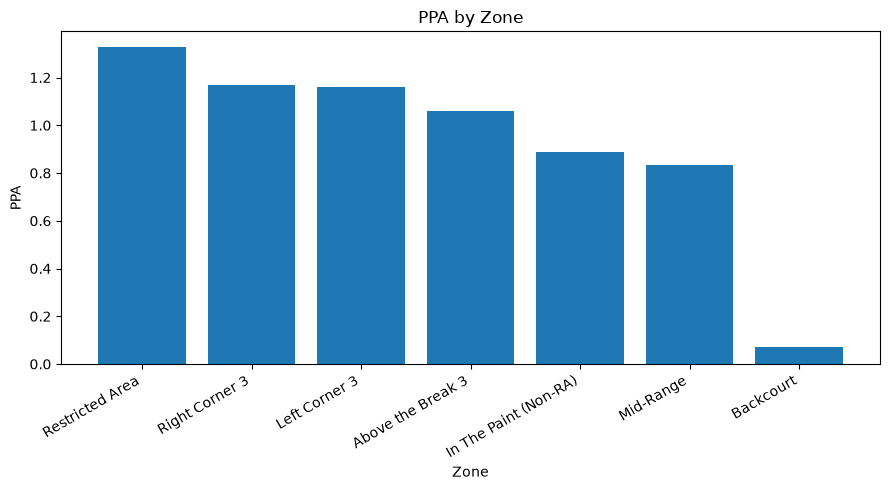

In [30]:
zone_sorted = zone_summary.sort_values('ppa', ascending = False)
# We will keep the backcourt shots for full authenticity of all shot attempts.
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(zone_sorted.index, zone_sorted['ppa'])
ax.set_title('PPA by Zone')
ax.set_xlabel('Zone')
ax.set_ylabel('PPA')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../visualizations/zone_efficiency.png', dpi=200, bbox_inches='tight')
plt.show()

## Stage 4: Zone Efficiency and League Trends

In [31]:
shots_all = pd.read_csv('../data/shots_2024_25.csv', dtype={'GAME_ID': str})
add_points(shots_all)
missed = shots_all[shots_all['SHOT_MADE_FLAG'] == 0]
print(missed.shape)
print(missed['POINTS'].sum())
print(shots_all['POINTS'].value_counts())

(116961, 26)
0
POINTS
0    116961
2     69262
3     33304
Name: count, dtype: int64


In [51]:
def new_zone_summary(df, grouping_column):
    zone_summary = df.groupby(grouping_column).agg(
            attempts = ('SHOT_MADE_FLAG', 'count'),
            makes = ('SHOT_MADE_FLAG', 'sum'),
            points = ('POINTS', 'sum'),
            fg_pct = ('SHOT_MADE_FLAG', 'mean'),
            ppa = ('POINTS', 'mean')
        )
    zone_summary['attempt_share'] = zone_summary['attempts'] / zone_summary['attempts'].sum()
    return zone_summary

In [52]:
print(new_zone_summary(shots_all, "SHOT_TYPE"))

                attempts  makes  points    fg_pct       ppa  attempt_share
SHOT_TYPE                                                                 
2PT Field Goal    127073  69262  138524  0.545057  1.090114       0.578849
3PT Field Goal     92454  33304   99912  0.360222  1.080667       0.421151


In [53]:
print(shots_all['SHOT_DISTANCE'].describe())

count    219527.000000
mean         14.003617
std          10.698004
min           0.000000
25%           3.000000
50%          13.000000
75%          25.000000
max          85.000000
Name: SHOT_DISTANCE, dtype: float64


In [54]:
bin = []
for i in range(37):
    bin.append(i)
shots_all['DISTANCE_BIN'] = pd.cut(shots_all['SHOT_DISTANCE'], bins = bin, right = False, labels = None)
bin_summary = new_zone_summary(shots_all, "DISTANCE_BIN")
print(bin_summary)
# We will drop all the shots that are beyond 36 feet.
# In the 2025-26 Season, the NBA made a rule where shots missed from at least 36 feet in the final three seconds of the first three quarters
# count as team misses rather than hurting an individual player's shooting percentage. So we will set that as the cutoff for this data.

              attempts  makes  points    fg_pct       ppa  attempt_share
DISTANCE_BIN                                                            
[0, 1)           14679  11167   22334  0.760747  1.521493       0.067093
[1, 2)           19189  13951   27902  0.727031  1.454062       0.087706
[2, 3)           15766   9462   18924  0.600152  1.200304       0.072061
[3, 4)           11556   6023   12046  0.521201  1.042402       0.052818
[4, 5)            8138   3673    7346  0.451339  0.902679       0.037196
[5, 6)            7008   3110    6220  0.443779  0.887557       0.032031
[6, 7)            6386   2731    5462  0.427654  0.855308       0.029188
[7, 8)            5206   2227    4454  0.427776  0.855551       0.023795
[8, 9)            4648   2096    4192  0.450947  0.901893       0.021244
[9, 10)           4083   1796    3592  0.439873  0.879745       0.018662
[10, 11)          4068   1829    3658  0.449607  0.899213       0.018593
[11, 12)          3890   1735    3470  0.446015  0.

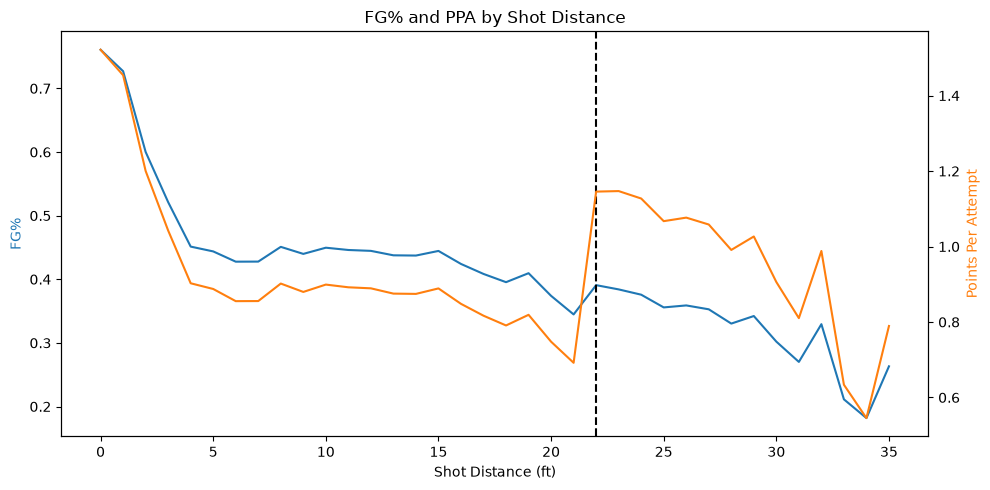

In [ ]:
fig, ax1 = plt.subplots(figsize = (10,5))
ax1.plot(bin, bin_summary['fg_pct'], color='tab:blue', label='FG%')
ax1.set_xlabel('Shot Distance (ft)')
ax1.set_ylabel('FG%', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(bin, bin_summary['ppa'], color='tab:orange', label='PPA')
ax2.set_ylabel('Points Per Attempt', color='tab:orange')

# Where the Corner 3 Pointer Distance Starts
ax1.axvline(22, color='black', linestyle='--')

plt.title("FG% and PPA by Shot Distance")
plt.tight_layout()
plt.savefig('../visualizations/distance_efficiency.png', dpi=200, bbox_inches='tight')
plt.show()

## Stage 5: Player Shooting Profiles

In [81]:
player_summary = new_zone_summary(shots_all, 'PLAYER_ID')
print(player_summary.describe())
print(player_summary.quantile([0.25, 0.5, 0.75]))

          attempts       makes       points      fg_pct         ppa  \
count   566.000000  566.000000   566.000000  566.000000  566.000000   
mean    387.856890  181.212014   421.265018    0.448490    1.039805   
std     357.055533  171.035123   392.987586    0.110231    0.232281   
min       1.000000    0.000000     0.000000    0.000000    0.000000   
25%      92.500000   41.000000    94.250000    0.406329    0.970042   
50%     287.000000  134.000000   307.000000    0.448074    1.066638   
75%     582.000000  271.750000   640.250000    0.496238    1.150729   
max    1656.000000  860.000000  1883.000000    1.000000    2.500000   

       attempt_share  
count     566.000000  
mean        0.001767  
std         0.001626  
min         0.000005  
25%         0.000421  
50%         0.001307  
75%         0.002651  
max         0.007543  
      attempts   makes  points    fg_pct       ppa  attempt_share
0.25      92.5   41.00   94.25  0.406329  0.970042       0.000421
0.50     287.0  134.0

The cutoff will be set at 174 attempts. This is because the NBA requires players to play 58 games to be considered as leaders for statistics such as scoring champion, assist champion, etc. To get to 174, you multiply those 58 games by a minimum of 3 shots a game. That way, the role players who still play but focus on aspects besides scoring are still considered but also the higher volume scorers who may have got hurt early will still easily meet the threshold.

In [82]:
min_attempts = 174

shots_all['IS_THREE'] = shots_all['SHOT_TYPE'] == '3PT Field Goal'
three_rate = shots_all.groupby('PLAYER_ID')['IS_THREE'].mean()
print(three_rate)

shots_all['IS_MIDRANGE'] = shots_all['SHOT_ZONE_BASIC'] == 'Mid-Range'
midrange_rate = shots_all.groupby('PLAYER_ID')['IS_MIDRANGE'].mean()
print(midrange_rate)

shots_all['IS_RESTRICTED'] = shots_all['SHOT_ZONE_BASIC'] == 'Restricted Area'
restricted_rate = shots_all.groupby('PLAYER_ID')['IS_RESTRICTED'].mean()
print(restricted_rate)

PLAYER_ID
2544       0.311811
101108     0.636364
200768     0.752137
200782     0.857143
201142     0.330961
             ...   
1642461    0.500000
1642484    0.636364
1642502    0.500000
1642505    0.700000
1642530    0.766667
Name: IS_THREE, Length: 566, dtype: float64
PLAYER_ID
2544       0.171654
101108     0.222985
200768     0.076923
200782     0.142857
201142     0.254448
             ...   
1642461    0.058824
1642484    0.060606
1642502    0.000000
1642505    0.066667
1642530    0.100000
Name: IS_MIDRANGE, Length: 566, dtype: float64
PLAYER_ID
2544       0.303937
101108     0.029160
200768     0.051282
200782     0.000000
201142     0.110320
             ...   
1642461    0.205882
1642484    0.060606
1642502    0.000000
1642505    0.133333
1642530    0.066667
Name: IS_RESTRICTED, Length: 566, dtype: float64


In [84]:
player_summary['three_rate'] = three_rate
player_summary['midrange_rate'] = midrange_rate
player_summary['restricted_rate'] = restricted_rate

player_summary = player_summary.drop(columns=['attempt_share'])


In [85]:
print(player_summary.shape)
print(player_summary.head())
print(player_summary[['three_rate', 'midrange_rate', 'restricted_rate']].describe())

(566, 8)
           attempts  makes  points    fg_pct       ppa  three_rate  \
PLAYER_ID                                                            
2544           1270    651    1451  0.512598  1.142520    0.311811   
101108          583    249     638  0.427101  1.094340    0.636364   
200768          117     41     111  0.350427  0.948718    0.752137   
200782            7      3       9  0.428571  1.285714    0.857143   
201142         1124    592    1344  0.526690  1.195730    0.330961   

           midrange_rate  restricted_rate  
PLAYER_ID                                  
2544            0.171654         0.303937  
101108          0.222985         0.029160  
200768          0.076923         0.051282  
200782          0.142857         0.000000  
201142          0.254448         0.110320  
       three_rate  midrange_rate  restricted_rate
count  566.000000     566.000000       566.000000
mean     0.427145       0.077231         0.298001
std      0.215904       0.068979         0

In [ ]:
names = shots_all[['PLAYER_ID', 'PLAYER_NAME']].drop_duplicates()
print(names['PLAYER_ID'].duplicated().sum())
print(player_summary.shape[0])

player_summary = player_summary.reset_index().merge(names, on='PLAYER_ID')
print(player_summary.shape[0])

0
566
566


In [92]:
qualified = player_summary[player_summary['attempts'] >= min_attempts]
print(len(qualified))

cols = ['PLAYER_NAME', 'attempts', 'fg_pct', 'ppa']

top_three = qualified.sort_values('three_rate', ascending=False).head(10)
print(top_three[cols + ['three_rate']])

top_midrange = qualified.sort_values('midrange_rate', ascending=False).head(10)
print(top_midrange[cols + ['midrange_rate']])

top_restricted = qualified.sort_values('restricted_rate', ascending=False).head(10)
print(top_restricted[cols + ['restricted_rate']])

351
          PLAYER_NAME  attempts    fg_pct       ppa  three_rate
275       Sam Merrill       424  0.405660  1.134434    0.867925
422          AJ Green       424  0.429245  1.224057    0.856132
12      Nicolas Batum       238  0.436975  1.243697    0.852941
235  Garrison Mathews       257  0.396887  1.124514    0.848249
407     Caleb Houstan       190  0.421053  1.178947    0.842105
322        Sam Hauser       474  0.451477  1.253165    0.841772
236         Dean Wade       271  0.413284  1.121771    0.819188
122        Lonzo Ball       243  0.366255  1.008230    0.802469
260        Isaiah Joe       588  0.440476  1.207483    0.792517
203         Max Strus       373  0.442359  1.187668    0.785523
          PLAYER_NAME  attempts    fg_pct       ppa  midrange_rate
16      DeMar DeRozan      1308  0.477064  1.018349       0.489297
102    Brandon Ingram       333  0.465465  1.060060       0.303303
43    Khris Middleton       337  0.474777  1.091988       0.299703
89   Bobby Portis Jr.   

            three_rate       ppa
three_rate    1.000000 -0.175091
ppa          -0.175091  1.000000


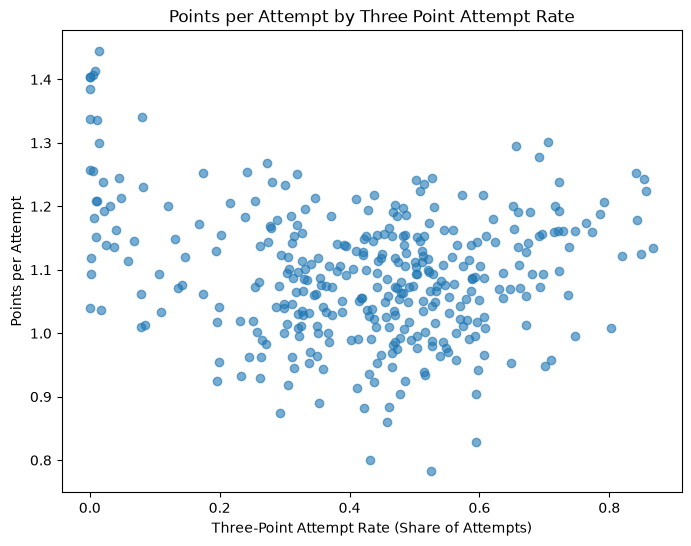

In [95]:
print(qualified[['three_rate', 'ppa']].corr())

fix, ax = plt.subplots(figsize=(8,6))
ax.scatter(qualified['three_rate'], qualified['ppa'], alpha=0.6)
ax.set_xlabel("Three-Point Attempt Rate (Share of Attempts)")
ax.set_ylabel("Points per Attempt")
ax.set_title("Points per Attempt by Three Point Attempt Rate")
plt.savefig('../visualizations/player_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## Stage 6: Player vs League Benchmarking

In [97]:
zone_map = {
    'Left Corner 3': 'Corner 3',
    'Right Corner 3': 'Corner 3',
}
shots_all['ZONE'] = shots_all['SHOT_ZONE_BASIC'].replace(zone_map)
bench_shots = shots_all[shots_all['ZONE'] != 'Backcourt']

- Merging the corners has been done to maintain simplicity of the zones as no other zones are seperated by side of the court.
- Backcourt was dropped because in the recent seasons, shots beyond 36 ft in the last 3 seconds of the first three quarters of games are not being counted towards players FG% and therefore, it only makes to remove these shots from this data because the rule was only introduced in the 2025-26 NBA season.

In [ ]:
league_zone = bench_shots.groupby('ZONE').agg(
    league_attempts = ('POINTS', 'count'),
    league_points = ('POINTS', 'sum')
)
league_zone['league_ppa'] = league_zone['league_points'] / league_zone['league_attempts']

In [110]:
player_zone = bench_shots.groupby(['PLAYER_ID', 'ZONE']).agg(
    attempts = ('POINTS', 'count'),
    points = ('POINTS', 'sum')
).reset_index()
player_zone['ppa'] = player_zone['points'] / player_zone['attempts']

In [111]:
player_zone = player_zone.merge(league_zone[['league_ppa']], on='ZONE')
player_zone['ppa_diff'] = player_zone['ppa'] - player_zone['league_ppa']
player_zone['points_vs_league'] = player_zone['ppa_diff'] * player_zone['attempts']

In [113]:
min_attempts = {
    'Above the Break 3': 50,
    'In The Paint (Non-RA)': 50,
    'Mid-Range': 50,
    'Restricted Area': 50,
    'Corner 3': 30,
}
player_zone['min_needed'] = player_zone['ZONE'].map(min_attempts)
qualified_zone = player_zone[player_zone['attempts'] >= player_zone['min_needed']]

names = shots_all[['PLAYER_ID', 'PLAYER_NAME']].drop_duplicates()
qualified_zone = qualified_zone.merge(names, on='PLAYER_ID')

print(qualified_zone.shape)
print(qualified_zone.head())

(1343, 10)
   PLAYER_ID                   ZONE  attempts  points       ppa  league_ppa  \
0       2544      Above the Break 3       357     408  1.142857    1.059525   
1       2544               Corner 3        37      39  1.054054    1.163748   
2       2544  In The Paint (Non-RA)       270     240  0.888889    0.887420   
3       2544              Mid-Range       218     190  0.871560    0.834128   
4       2544        Restricted Area       386     574  1.487047    1.327112   

   ppa_diff  points_vs_league  min_needed   PLAYER_NAME  
0  0.083332         29.749627          50  LeBron James  
1 -0.109694         -4.058681          30  LeBron James  
2  0.001469          0.396627          50  LeBron James  
3  0.037432          8.160172          50  LeBron James  
4  0.159934         61.734663          50  LeBron James  


In [116]:
print(qualified_zone[qualified_zone['ZONE'] == 'Above the Break 3'].sort_values('ppa_diff', ascending=False).head(10))
print(qualified_zone[qualified_zone['ZONE'] == 'Corner 3'].sort_values('ppa_diff', ascending=False).head(10))
print(qualified_zone[qualified_zone['ZONE'] == 'In The Paint (Non-RA)'].sort_values('ppa_diff', ascending=False).head(10))
print(qualified_zone[qualified_zone['ZONE'] == 'Mid-Range'].sort_values('ppa_diff', ascending=False).head(10))
print(qualified_zone[qualified_zone['ZONE'] == 'Restricted Area'].sort_values('ppa_diff', ascending=False).head(10))


      PLAYER_ID               ZONE  attempts  points       ppa  league_ppa  \
80       202692  Above the Break 3       103     138  1.339806    1.059525   
1099    1631216  Above the Break 3       104     138  1.326923    1.059525   
163      203897  Above the Break 3       442     585  1.323529    1.059525   
1106    1631222  Above the Break 3       102     135  1.323529    1.059525   
1176    1641727  Above the Break 3        55      72  1.309091    1.059525   
223      203999  Above the Break 3       294     384  1.306122    1.059525   
677     1629660  Above the Break 3       212     276  1.301887    1.059525   
997     1631093  Above the Break 3       118     153  1.296610    1.059525   
1235    1641810  Above the Break 3        81     105  1.296296    1.059525   
332     1627752  Above the Break 3       160     207  1.293750    1.059525   

      ppa_diff  points_vs_league  min_needed      PLAYER_NAME  
80    0.280281         28.868940          50       Alec Burks  
1099  0.26739

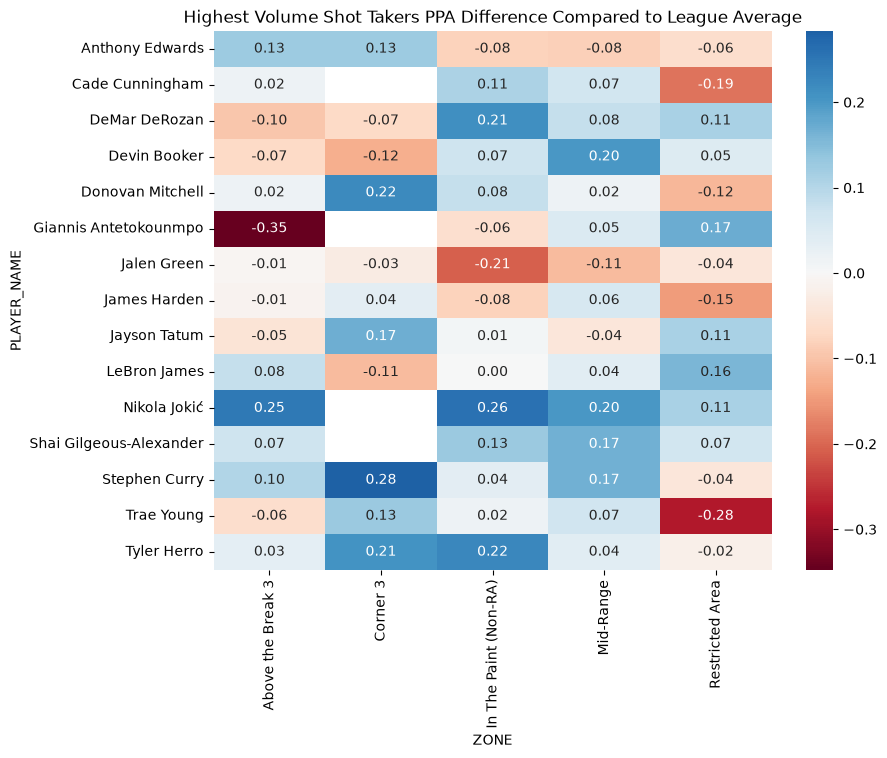

In [121]:
top_players = player_summary.sort_values('attempts', ascending=False).head(15)['PLAYER_NAME']

heat_data = qualified_zone[qualified_zone['PLAYER_NAME'].isin(top_players)]
heat = heat_data.pivot(index='PLAYER_NAME', columns='ZONE', values='ppa_diff')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(heat, cmap='RdBu', center=0, annot=True, fmt='.2f', ax=ax)
ax.set_title('Highest Volume Shot Takers PPA Difference Compared to League Average')
plt.savefig('../visualizations/benchmark_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

## Findings log
- 2PT vs 3PT: Shots in the restricted area produce by far the highest PPA at over 1.2 PPA. After that though, the 3 pointers (including both corners and above the break) are in between that 1-1.2 PPA range. Below that 1 PPA range are the rest of the 2 point shots and shots attempted from the backcourt. This likely occurs because shots in the restricted area are typically a lot simpler such as open layups and dunks so they have an extremely high conversion rate. When it comes to 3 pointers, they provide more points for each make so naturally, even with a lower conversion rate, they will provide a higher PPA. The rest of the 2 point shots though, they can sometimes be just as difficult as 3 point attempts without that same extra point, leading an overall lower PPA for those shots. (These likely reasons, not determined facts).
- PPA by distance: lowest around 20 to 21 ft because these are those long mid-range shots that are highly dreaded in the modern NBA. These shots are almost the same difficulty as 3s while offering only 2 points, so naturally, their FG% will be similar to 3s but they are providing just 2 points, making the overal PPA hit a lower number Additionally, shots over about 33 ft tend to have a lower PPA and this is probably due to the difficulty of those shots as they are reaching a distance where only star players such as Stephen Curry, Damian Lillard, Trae Young (when he was in his prime) will actually shoot from on a consistent basis.
- Three-point rate vs PPA: r = -0.175 (weak negative), players with the lowest three-point rates have the highest PPA, possibly because they shoot mostly at the rim (hypothesis, not yet checked).
- Heatmap: Looking at the top 15 Players by PPA in the league, Giannis is by far the weakest from above the break 3s (compared to the league he is at -0.35) but he is also the strongest when it comes to shots in the restricted area (+0.17). Additionally, you can see that Cade Cunninghams PPA is clearly hiding his weakness when it comes to finishing in the restricted area. Many fans don't tend to think of Cade as a weak finisher since he is a 6'8 guard (which is on the taller side) but this data shows otherwise.